# Load the Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,LabelEncoder
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier
import pickle
from sklearn.model_selection import cross_val_score
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder

In [2]:
telco = pd.read_csv('Data.csv')

### Make the copy of the original dataset to work on

In [3]:
data = telco.copy()

In [4]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Dataset & Project Overview

### This project uses IBM’s Telco Customer Churn sample dataset, which represents customers of a fictional telecommunications company. The dataset contains information about customers’ demographics, tenure, subscribed services, contract types, payment methods, monthly charges, total charges, and whether they have churned.

### The business problem is to understand why customers leave the telecom company and identify customers who are likely to churn in the future. Using machine learning, we will predict each customer’s churn probability and combine it with their monthly charges to estimate the potential revenue at risk.

# Column Description

- `customerID` is the primary key or the unique identifier for each customer

- `gender` tells us about the gender of the customer, we have 2 categories in it, Male and Female

- `SeniorCitizen` Whether the customer is a senior citizen or not (1, 0)

- `Partner` Whether the customer has a partner or not (Yes, No)

- `Dependents` Whether the customer has dependents or not (Yes, No), Dependents usually means whether the customer has people who financially depend on them, such as children or a spouse/family member.

- `tenure` Number of months the customer has stayed with the company

- `PhoneService` Whether the customer has a phone service or not (Yes, No)

- `MultipleLines` Whether the customer has multiple lines or not (Yes, No, No phone service)

- `InternetService` Customer’s internet service provider (DSL, Fiber optic, No)

- `OnlineSecurity` Whether the customer has online security or not (Yes, No, No internet service)

- `OnlineBackup` Whether the customer has online backup or not (Yes, No, No internet service)

- `DeviceProtection` Whether the customer has device protection or not (Yes, No, No internet service)

- `TechSupport` Whether the customer has tech support or not (Yes, No, No internet service)

- `StreamingTV` Whether the customer has streaming TV or not (Yes, No, No internet service)

- `StreamingMovies` Whether the customer has streaming movies or not (Yes, No, No internet service)

- `Contract` The contract term of the customer (Month-to-month, One year, Two year)

- `PaperlessBilling` Whether the customer has paperless billing or not (Yes, No)

- `PaymentMethod` The customer’s payment method (Electronic check, Mailed check, Bank transfer (automatic), Credit card

- `MonthlyCharges` The amount charged to the customer monthly

- `TotalCharges` The total amount charged to the customer

- `Churn` Whether the customer churned or not (Yes or No)

# Issues with the dataset


# Messy Data

- ### Change the datatype for Total Charges to float, it is currently object type. It had some values as '  ' so convert them to np.nan and make the column float.






## Inconsistent

- ### Inconsistent column names some starts with upper case and some with lower case, so convert them all in the same case

## Missing
- ### After we made the ' ' values in the Totalcharges column nan now we have 11 missing values in `Totalcharges`






# -----------------------------------------------------------------------------

# Let's start

### Fixed the column names and made the first letter captial and all rest lower

In [5]:
data.columns = data.columns.str.capitalize()

In [6]:
data.head()

,Customerid,Gender,Seniorcitizen,Partner,Dependents,Tenure,Phoneservice,Multiplelines,Internetservice,Onlinesecurity,...,Deviceprotection,Techsupport,Streamingtv,Streamingmovies,Contract,Paperlessbilling,Paymentmethod,Monthlycharges,Totalcharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### No Duplicate Data
 


In [7]:
data[data.duplicated()]

,Customerid,Gender,Seniorcitizen,Partner,Dependents,Tenure,Phoneservice,Multiplelines,Internetservice,Onlinesecurity,...,Deviceprotection,Techsupport,Streamingtv,Streamingmovies,Contract,Paperlessbilling,Paymentmethod,Monthlycharges,Totalcharges,Churn


In [8]:
data.head()

,Customerid,Gender,Seniorcitizen,Partner,Dependents,Tenure,Phoneservice,Multiplelines,Internetservice,Onlinesecurity,...,Deviceprotection,Techsupport,Streamingtv,Streamingmovies,Contract,Paperlessbilling,Paymentmethod,Monthlycharges,Totalcharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Dropping the unnecessary column

In [9]:
data.drop('Customerid',axis=1,inplace=True)

### Find the '' values in the Totalcharges column

In [10]:
data[data['Totalcharges'].str.strip() =='']

,Gender,Seniorcitizen,Partner,Dependents,Tenure,Phoneservice,Multiplelines,Internetservice,Onlinesecurity,Onlinebackup,Deviceprotection,Techsupport,Streamingtv,Streamingmovies,Contract,Paperlessbilling,Paymentmethod,Monthlycharges,Totalcharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


# As we can see that in these Totalcharges column has just ' ' values and in the same rows the values in the Tenure column are 0

### Convert them to np.nan so that we can change it's datatype to float again.

In [11]:
data['Totalcharges'] = data['Totalcharges'].str.strip().replace('',np.nan)

### We will drop those rows as in the same rows the value in the tenure column is 0 so it won't be of much use for us

In [12]:
data = data.dropna(subset=['Totalcharges'])

In [13]:
data['Totalcharges'] = data['Totalcharges'].astype(dtype=float)

In [14]:
# Since we have 0 

In [15]:
data.isnull().sum()

Gender              0
Seniorcitizen       0
Partner             0
Dependents          0
Tenure              0
Phoneservice        0
Multiplelines       0
Internetservice     0
Onlinesecurity      0
Onlinebackup        0
Deviceprotection    0
Techsupport         0
Streamingtv         0
Streamingmovies     0
Contract            0
Paperlessbilling    0
Paymentmethod       0
Monthlycharges      0
Totalcharges        0
Churn               0
dtype: int64

# Univariate Analysis

### Extracted the categorical column names as well as the numerical ones.

In [16]:
categorical_columns = data.select_dtypes(include='object').columns.tolist()
numerical_columns = data.select_dtypes(exclude='object').columns.tolist()

In [17]:
numerical_columns.remove('Seniorcitizen')

In [18]:
categorical_columns.append('Seniorcitizen')

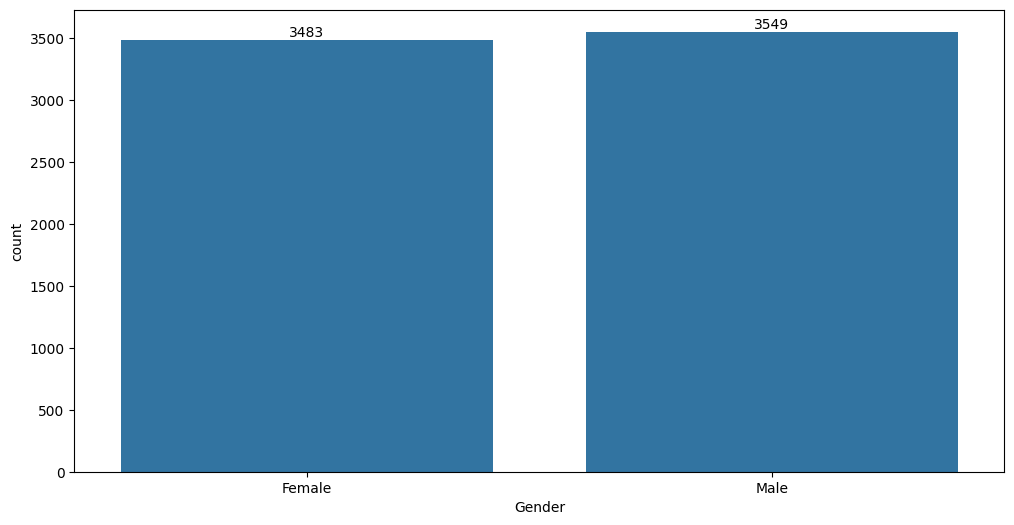

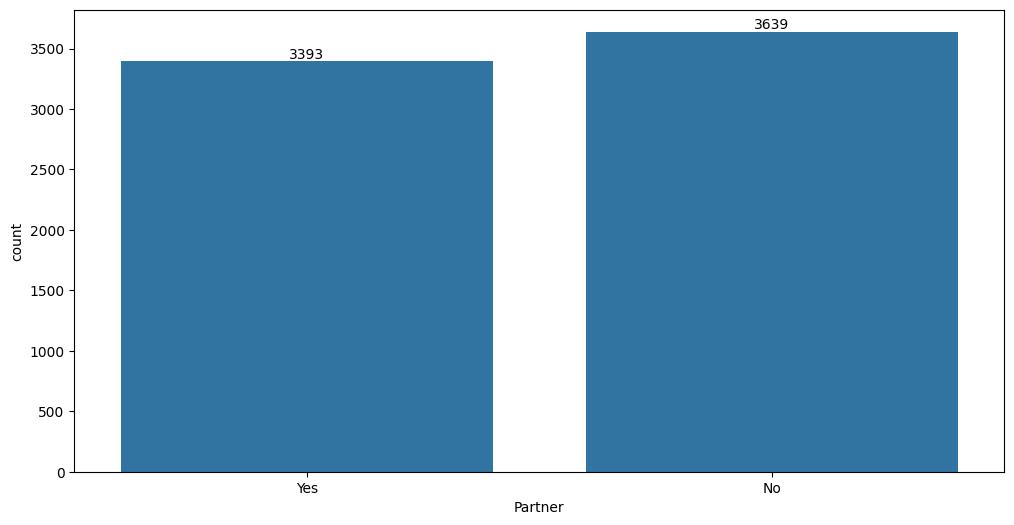

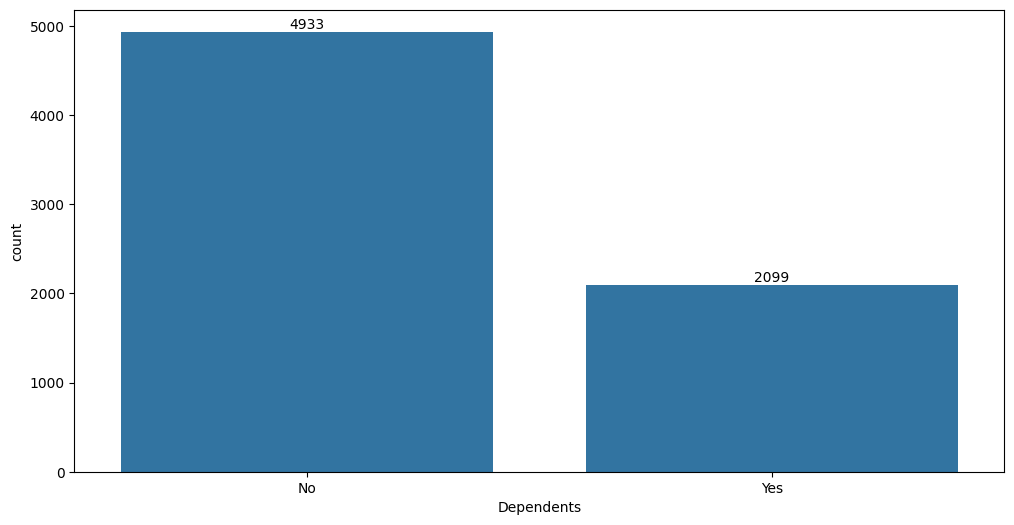

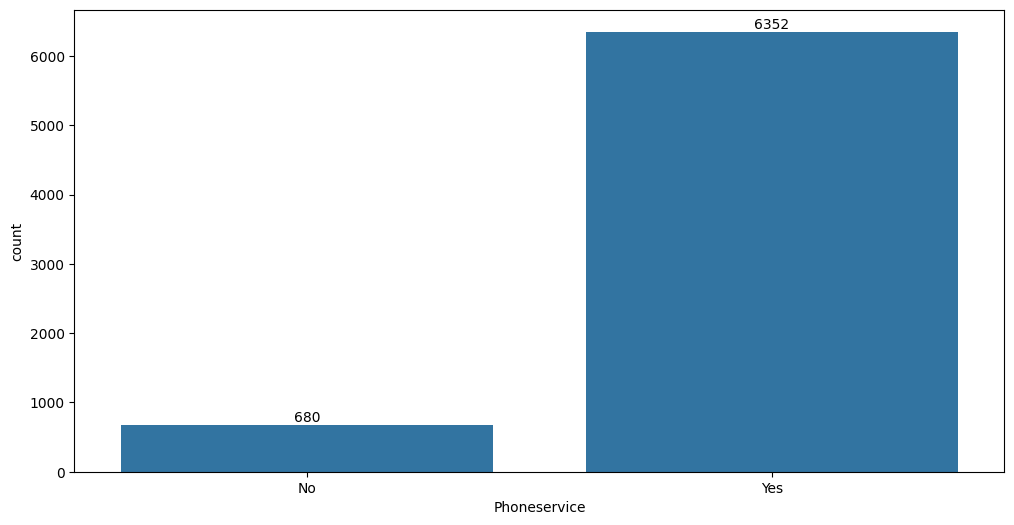

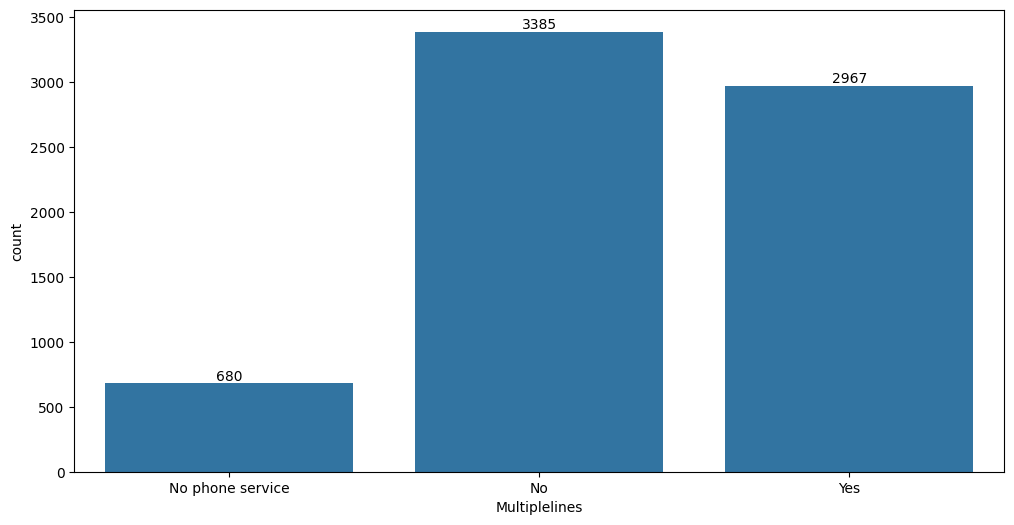

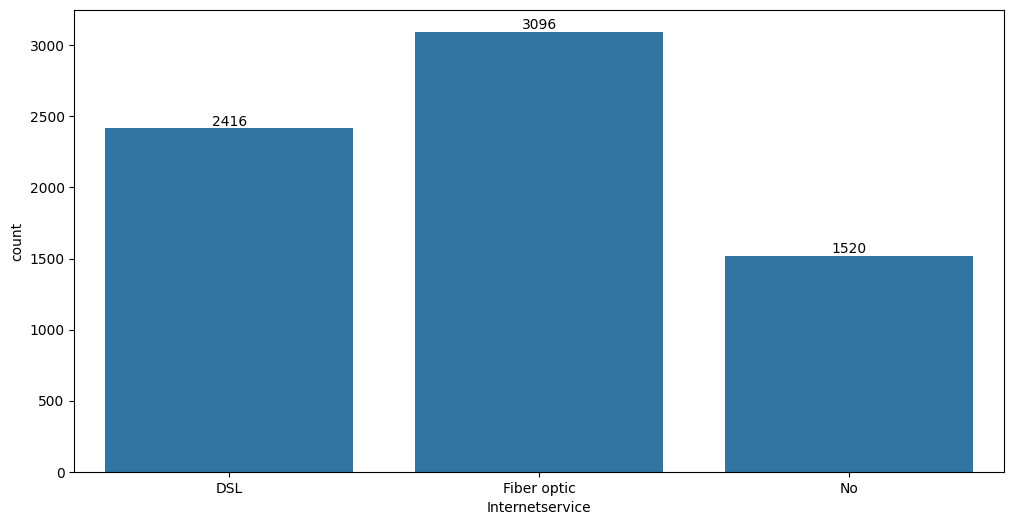

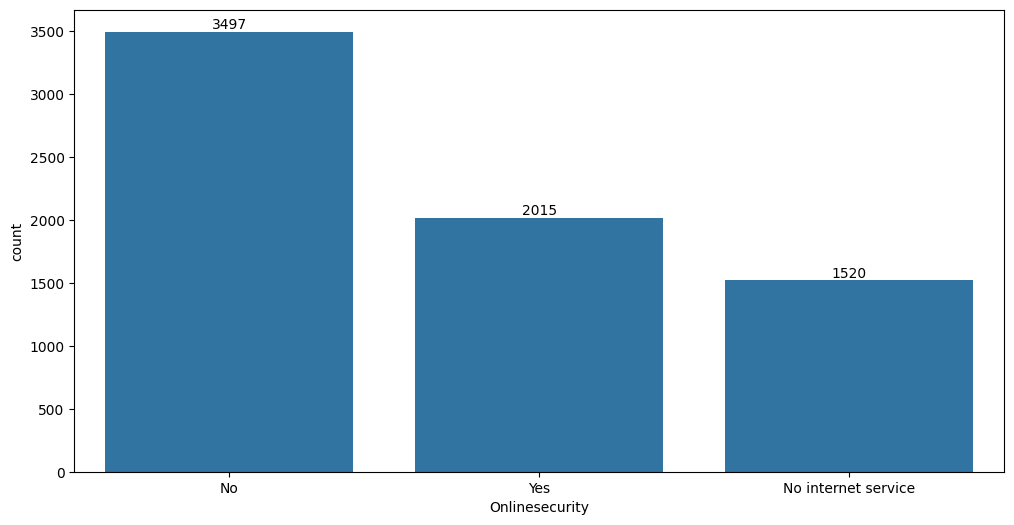

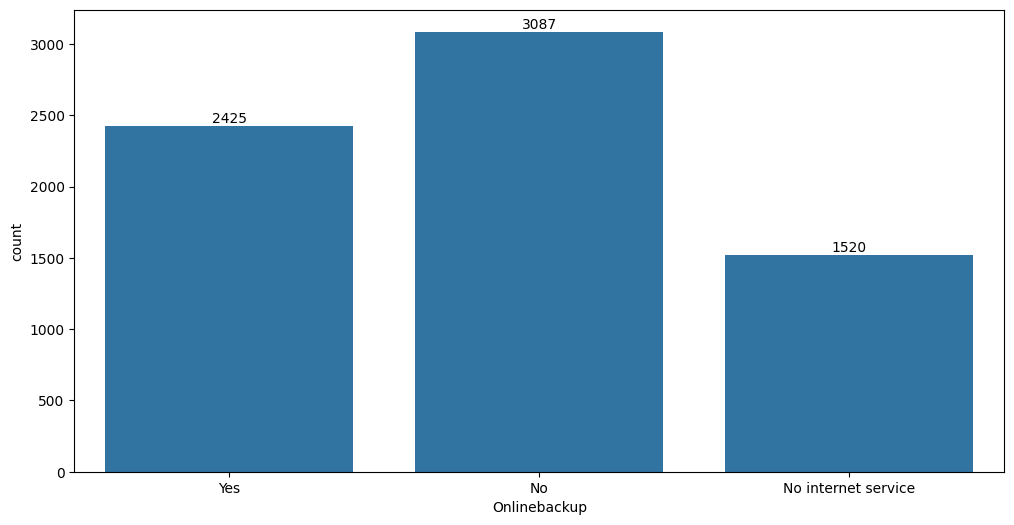

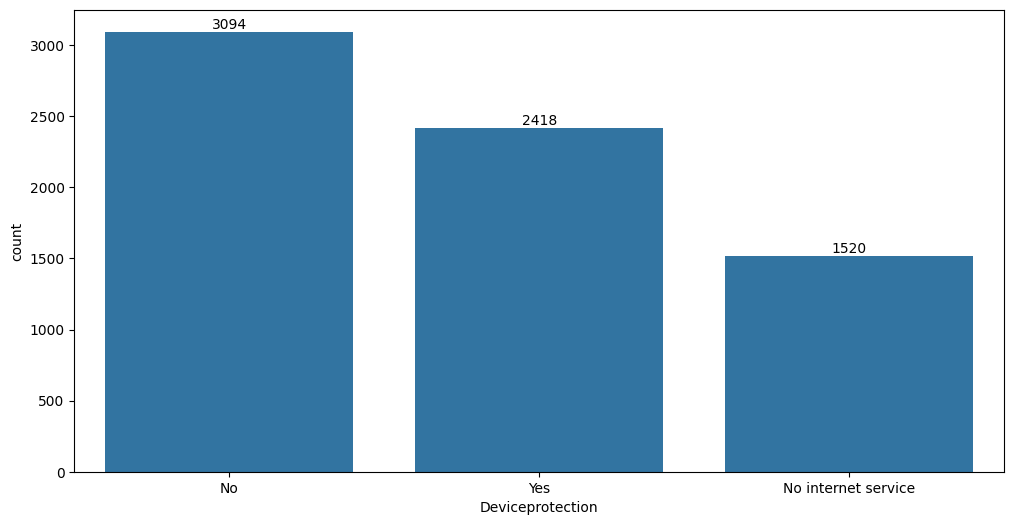

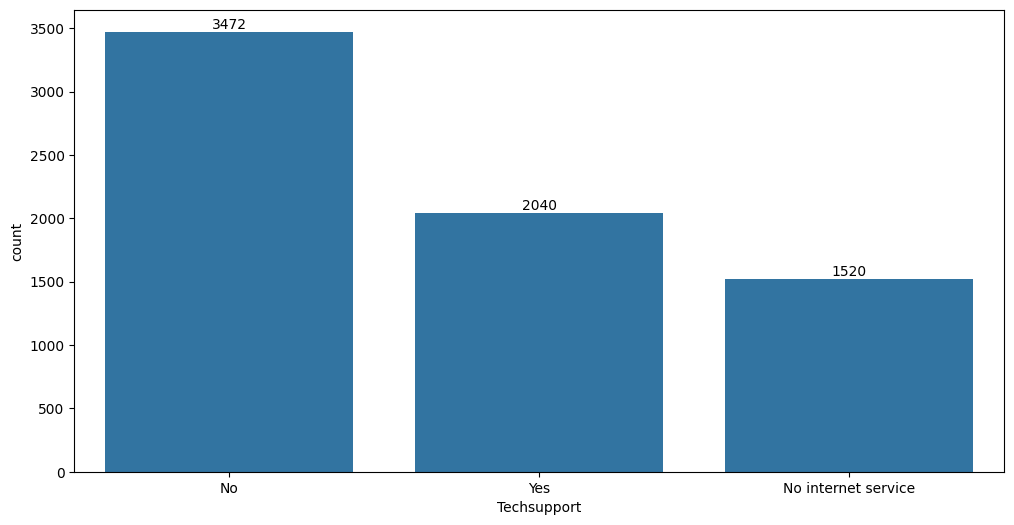

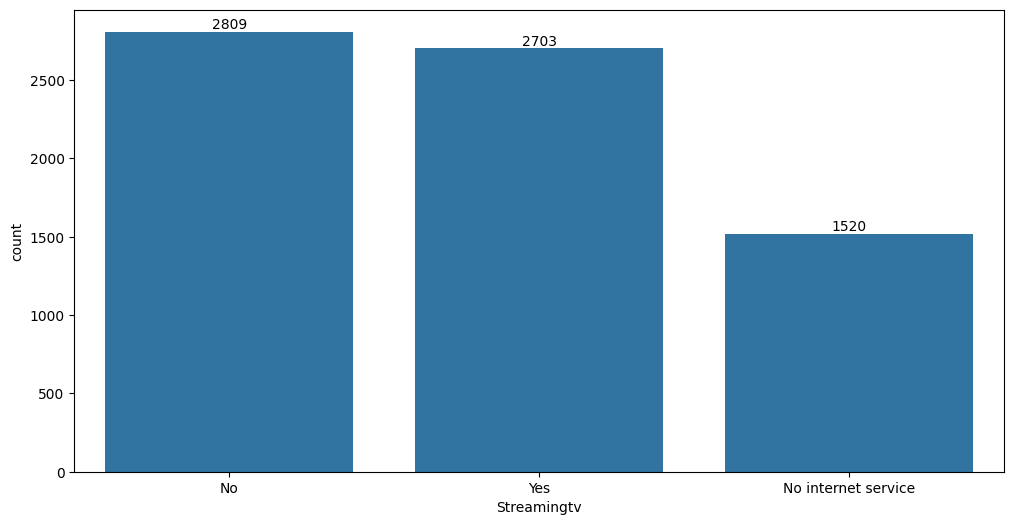

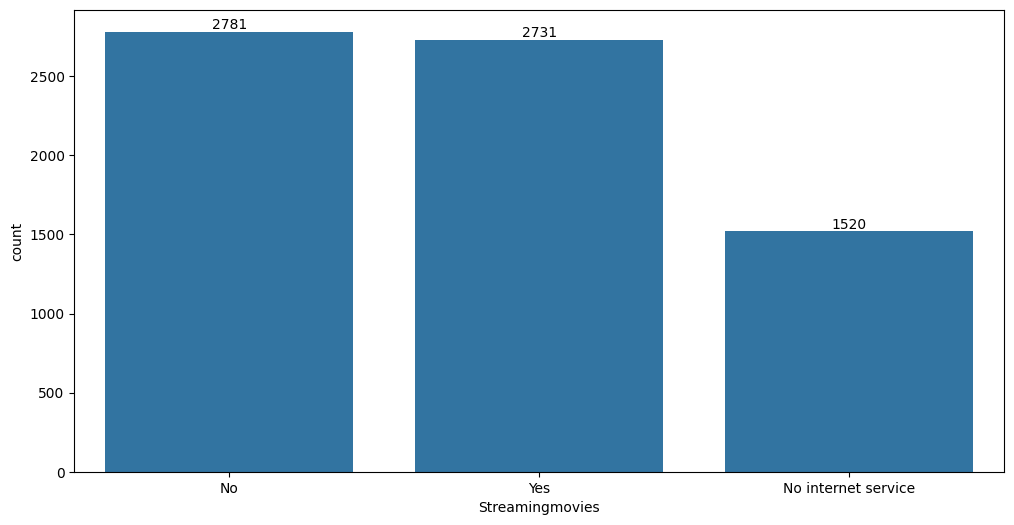

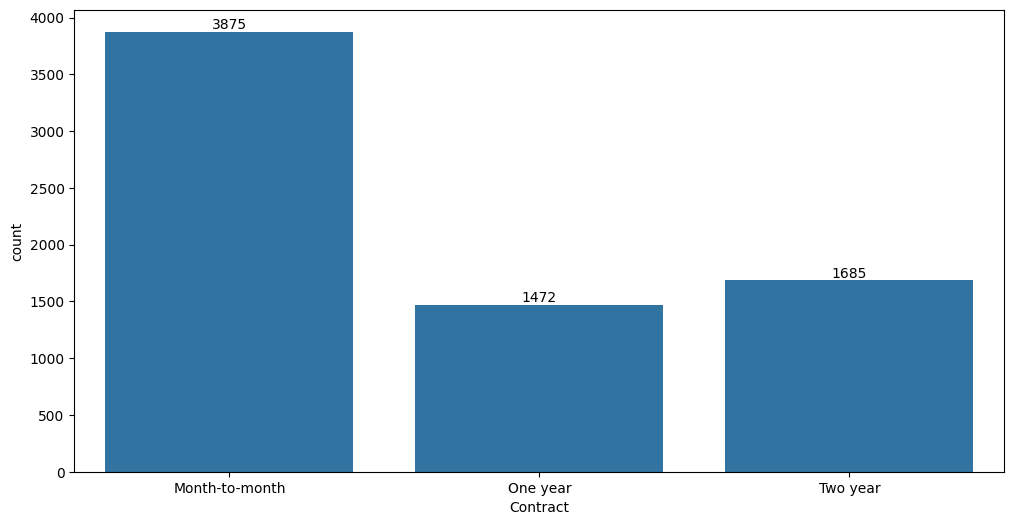

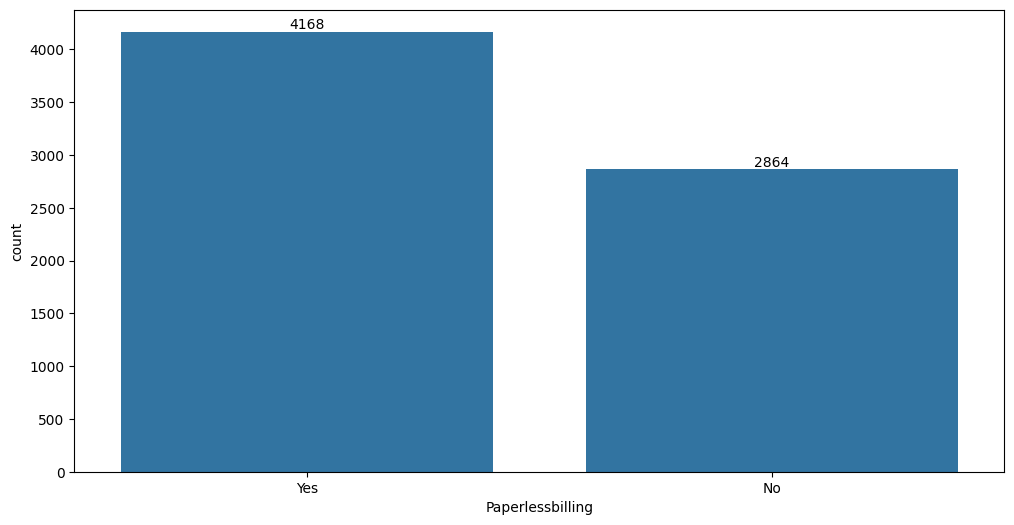

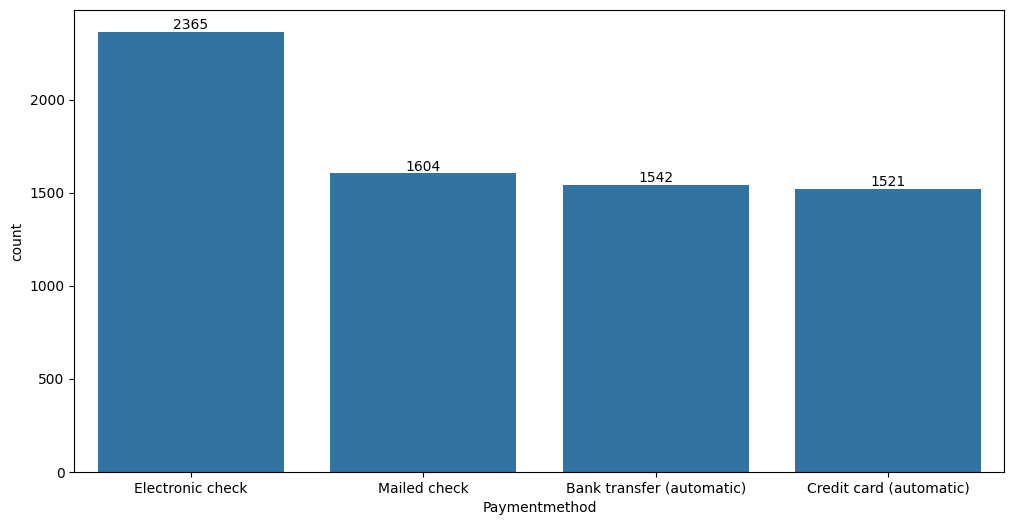

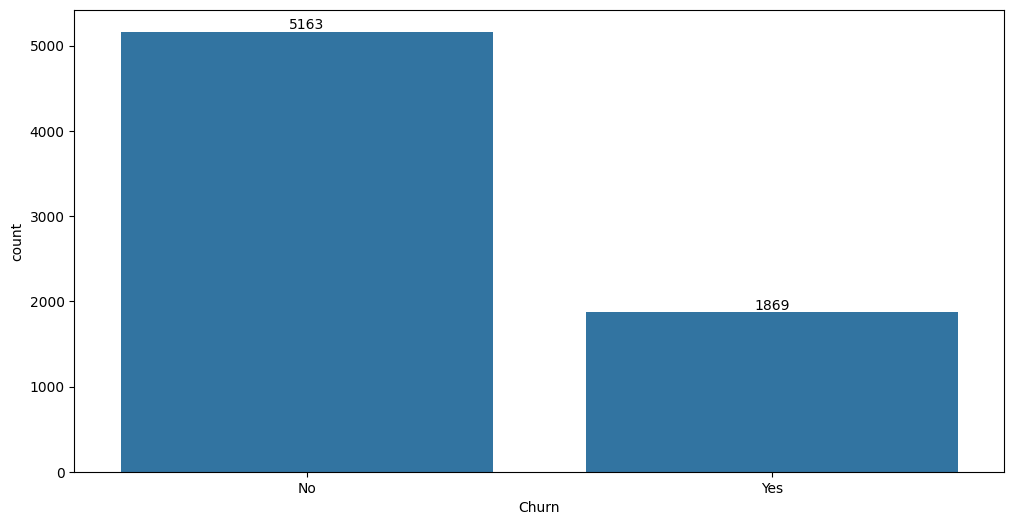

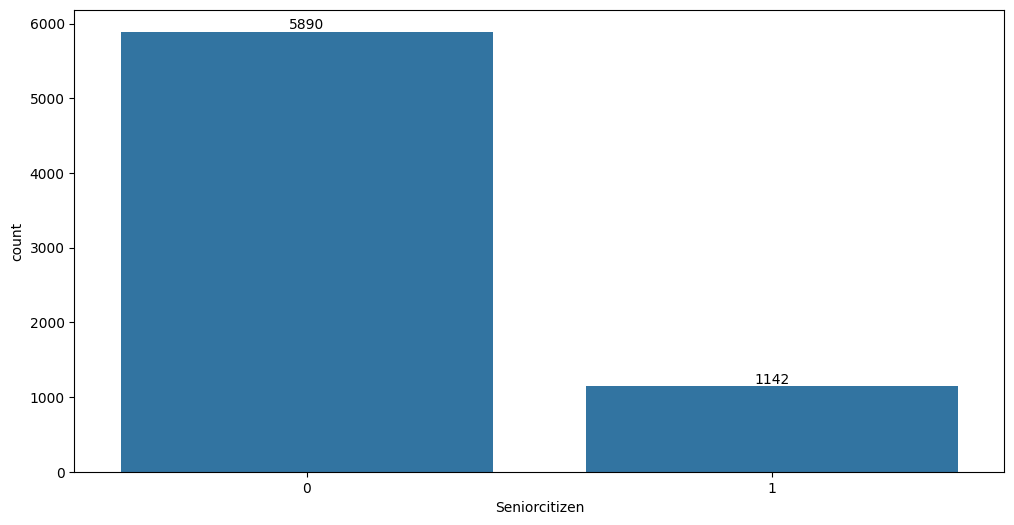

In [19]:
for i in categorical_columns:
    plt.figure(figsize=(12,6))
    ax= sns.countplot(data=data,x=i)
    ax.bar_label(ax.containers[0])
    plt.show()

# Things to keep in mind after the univariate analysis

- ### `Churn` Our Target column has Imbalanced data. We need to do something for it

## Plotted the Numerical Columns

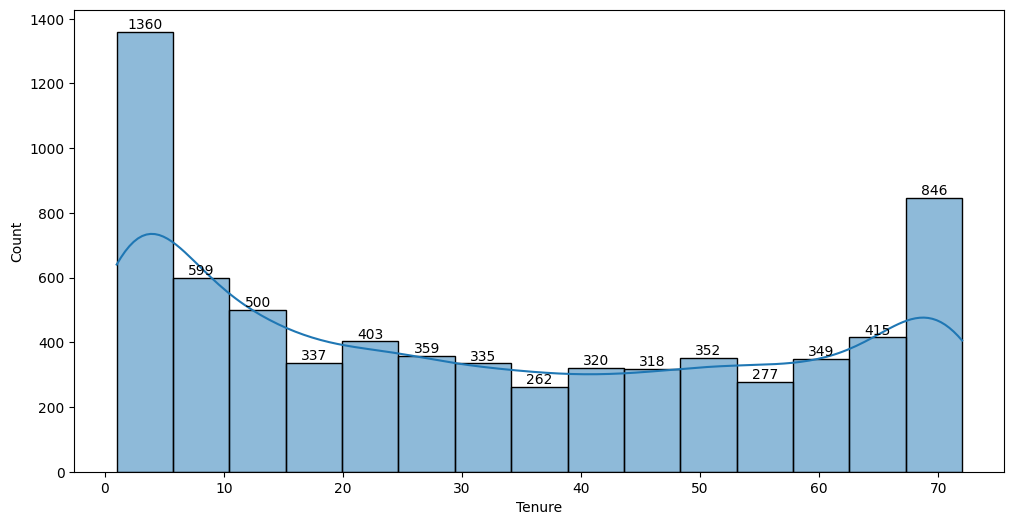

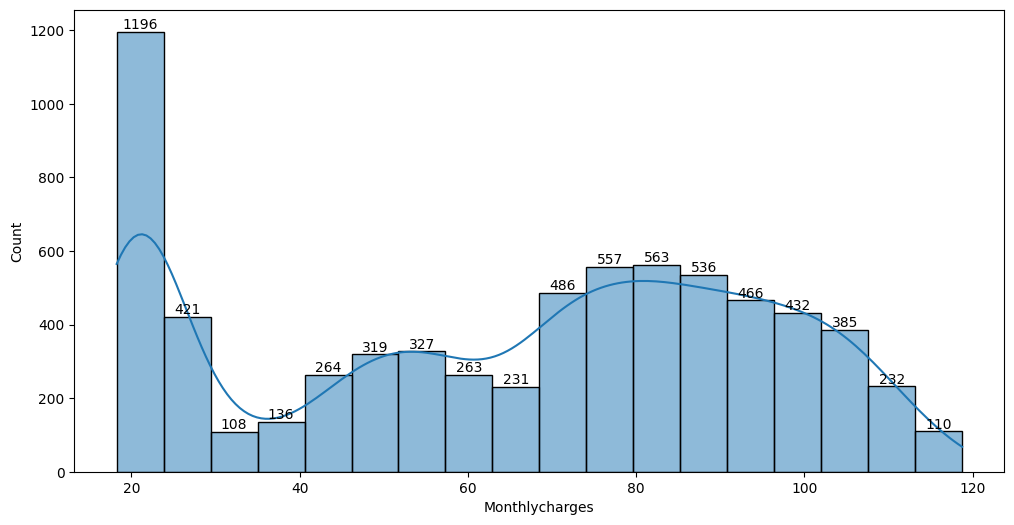

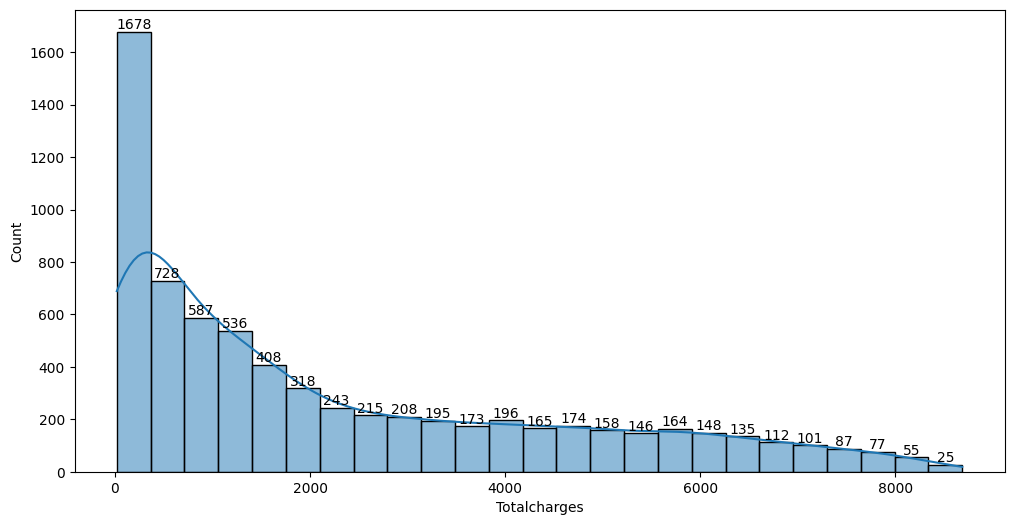

In [20]:
for i in numerical_columns:
    plt.figure(figsize=(12,6))
    ax = sns.histplot(data=data,x=i,kde=True)
    ax.bar_label(ax.containers[0])
    plt.show()

## Checking if there are any outliers in the Numerical Columns

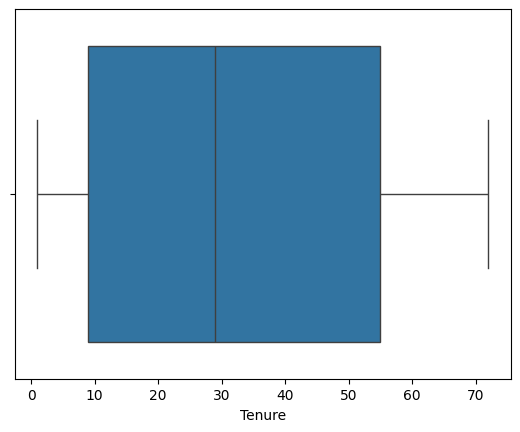

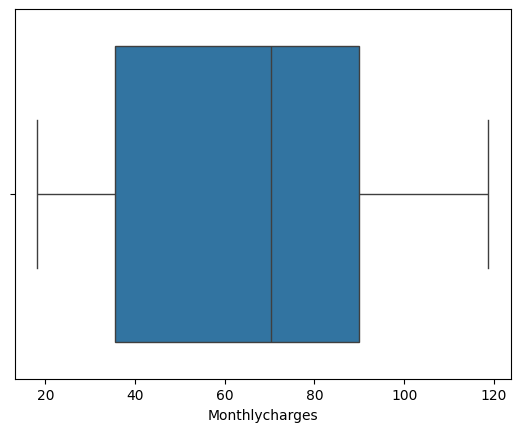

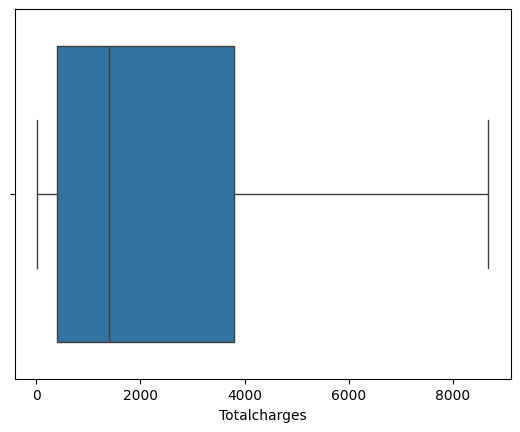

In [21]:
for i in numerical_columns:
    sns.boxplot(data=data,x=i)
    plt.show()

## Seeing if there are any outliers in numerical columns with the target column

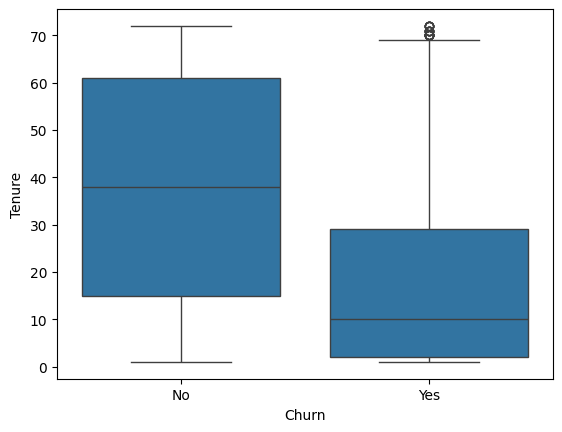

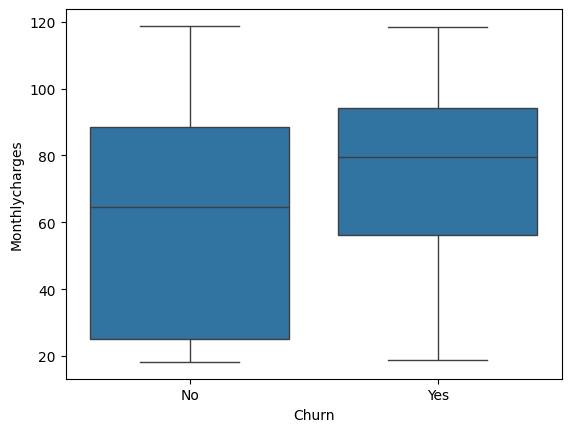

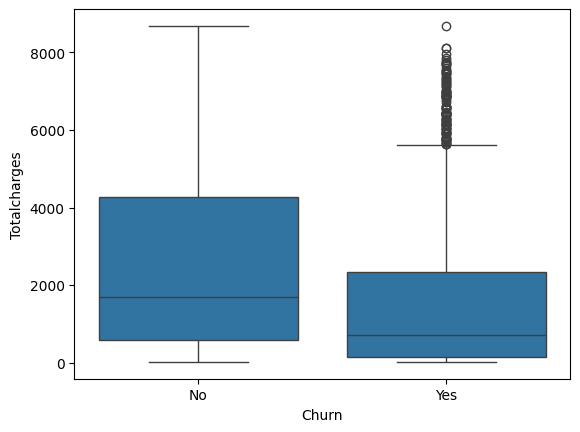

In [22]:
for num in numerical_columns:
    sns.boxplot(data=data, x='Churn', y=num)
    plt.show()

## Totalcharges column has a lot of outliers in the Yes category

### Hence finding the iqr range for Churn = yes and of Totalcharges column

In [23]:
iqr = data[data['Churn']=='Yes']['Totalcharges'].quantile(0.75)- data[data['Churn']=='Yes']['Totalcharges'].quantile(0.25)

In [24]:
iqr

np.float64(2196.8)

In [25]:
upper = data[data['Churn']=='Yes']['Totalcharges'].quantile(0.75) + (1.5*iqr)

In [26]:
lower = data[data['Churn']=='Yes']['Totalcharges'].quantile(0.25) - (1.5*iqr)

In [27]:
lower

np.float64(-3160.7000000000003)

In [28]:
upper

np.float64(5626.5)

In [29]:
data['Totalcharges'].describe()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: Totalcharges, dtype: float64

In [30]:
pd.set_option('display.max_columns',None)

In [31]:
data[data['Churn']=='Yes'].describe()

,Seniorcitizen,Tenure,Monthlycharges,Totalcharges
count,1869.000000,1869.000000,1869.000000,1869.000000
mean,0.254682,17.979133,74.441332,1531.796094
std,0.435799,19.531123,24.666053,1890.822994
min,0.000000,1.000000,18.850000,18.850000
25%,0.000000,2.000000,56.150000,134.500000
50%,0.000000,10.000000,79.650000,703.550000
75%,1.000000,29.000000,94.200000,2331.300000
max,1.000000,72.000000,118.350000,8684.800000


In [32]:
data[data['Churn']=='No'].describe()

,Seniorcitizen,Tenure,Monthlycharges,Totalcharges
count,5163.000000,5163.00000,5163.000000,5163.000000
mean,0.128995,37.65001,61.307408,2555.344141
std,0.335227,24.07694,31.094557,2329.456984
min,0.000000,1.00000,18.250000,18.800000
25%,0.000000,15.00000,25.100000,577.825000
50%,0.000000,38.00000,64.450000,1683.600000
75%,0.000000,61.00000,88.475000,4264.125000
max,1.000000,72.00000,118.750000,8672.450000


## To check the outliers if they are actual users or are just outliers only

In [33]:
data[(data['Churn']=='Yes') & ( (data['Totalcharges']>=upper)| (data['Totalcharges']<=lower) ) ].sort_values(by='Totalcharges',ascending=False)

,Gender,Seniorcitizen,Partner,Dependents,Tenure,Phoneservice,Multiplelines,Internetservice,Onlinesecurity,Onlinebackup,Deviceprotection,Techsupport,Streamingtv,Streamingmovies,Contract,Paperlessbilling,Paymentmethod,Monthlycharges,Totalcharges,Churn
4610,Male,0,Yes,No,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,One year,Yes,Bank transfer (automatic),117.80,8684.80,Yes
1306,Female,0,No,No,70,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,One year,No,Credit card (automatic),115.55,8127.60,Yes
3890,Female,0,Yes,No,72,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,One year,Yes,Electronic check,109.25,8109.80,Yes
6537,Male,0,Yes,No,70,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,One year,No,Credit card (automatic),115.65,7968.85,Yes
5581,Male,0,Yes,Yes,68,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Electronic check,113.15,7856.00,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4691,Female,1,Yes,No,56,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),100.65,5688.05,Yes
3415,Female,0,Yes,Yes,68,Yes,Yes,Fiber optic,No,No,No,No,Yes,No,One year,Yes,Electronic check,83.00,5685.80,Yes
6312,Male,0,No,No,54,Yes,No,Fiber optic,Yes,Yes,No,Yes,Yes,Yes,One year,Yes,Credit card (automatic),105.40,5643.40,Yes
5371,Female,0,No,No,54,Yes,Yes,Fiber optic,Yes,No,Yes,No,Yes,Yes,One year,Yes,Bank transfer (automatic),103.95,5639.05,Yes


In [34]:
data['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1685
One year          1472
Name: count, dtype: int64

## Turns out they are actual authentic users

# Feature Selection

In [35]:
data.head()

,Gender,Seniorcitizen,Partner,Dependents,Tenure,Phoneservice,Multiplelines,Internetservice,Onlinesecurity,Onlinebackup,Deviceprotection,Techsupport,Streamingtv,Streamingmovies,Contract,Paperlessbilling,Paymentmethod,Monthlycharges,Totalcharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [36]:
preprocessing_feature_selection = ColumnTransformer([

    ('Scaling',StandardScaler(),[4,17,18]),
    ('Encoding',OrdinalEncoder(),[0,2,3,5,6,7,8,9,10,11,12,13,14,15,16])

    
],remainder='passthrough')

In [37]:
rfe = RFE(LogisticRegression(),n_features_to_select=5)

In [38]:
feature_selection_pipe = Pipeline([

    ('Scaling',preprocessing_feature_selection),
    ('Rfe',rfe)
])

In [39]:
x = data.drop('Churn',axis=1)

In [40]:
y= data['Churn']

In [41]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,stratify=y,random_state=42)

In [42]:
x_train_selected = feature_selection_pipe.fit_transform(x_train,y_train)

In [43]:
feature_names = feature_selection_pipe.named_steps['Scaling'].get_feature_names_out()

In [44]:
selected_features = feature_names[
    feature_selection_pipe.named_steps['Rfe'].support_
]

### These are the best features according to the RFE

In [45]:
print(selected_features)

['Scaling__Tenure' 'Scaling__Monthlycharges' 'Scaling__Totalcharges'
 'Encoding__Phoneservice' 'Encoding__Contract']


In [46]:
rd = RandomForestClassifier()

In [47]:
score = cross_val_score(rd,x_train_selected,y_train,cv=5,scoring='accuracy')

# After taking all the 18 columns we got accuracy of 79%

In [48]:
score.mean()

np.float64(0.7681777777777777)

In [49]:
x = data[['Tenure','Monthlycharges','Totalcharges','Phoneservice','Contract']]

In [50]:
y = data['Churn']

In [51]:
y

0        No
1        No
2       Yes
3        No
4       Yes
       ... 
7038     No
7039     No
7040     No
7041    Yes
7042     No
Name: Churn, Length: 7032, dtype: object

In [52]:
transformer = ColumnTransformer([

    ('Scaling',StandardScaler(),[0,1,2]),
    ('Encoding',OrdinalEncoder(),[3,4])

    
],remainder='passthrough')

In [53]:
pipe = Pipeline([

    ('transformer',transformer)
])

In [54]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,stratify=y,random_state=42)

In [55]:
x_train_feature=pipe.fit_transform(x_train,y_train)

In [56]:
score = cross_val_score(rd,x_train_feature,y_train,cv=5,scoring='accuracy')

# Even with just those 5 features selected by RFE we got 76% accuracy 

In [57]:
score.mean()

np.float64(0.7664)

# Hence we will only use the 5 features then

## Let's start making our model now

In [58]:
from sklearn.model_selection import StratifiedKFold

In [59]:
kfold = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [60]:
x = data[['Tenure','Monthlycharges','Totalcharges','Phoneservice','Contract']]

In [61]:
y = data['Churn']

In [62]:
le = LabelEncoder()

In [63]:
y = le.fit_transform(y)

In [64]:
x.head()

,Tenure,Monthlycharges,Totalcharges,Phoneservice,Contract
0,1,29.85,29.85,No,Month-to-month
1,34,56.95,1889.50,Yes,One year
2,2,53.85,108.15,Yes,Month-to-month
3,45,42.30,1840.75,No,One year
4,2,70.70,151.65,Yes,Month-to-month


### Pipeline

In [65]:
preprocessing = ColumnTransformer([

    ('Scaling',StandardScaler(),[0,1,2]),
    ('Ordinal Encoding',OrdinalEncoder(),[3]),
    ('Ohe',OneHotEncoder(drop='first',sparse_output=False),[4])
    
],remainder='passthrough')

In [66]:
model = AdaBoostClassifier()

### We will use SMOTE because our target column `Churn` had imbalanced data

In [67]:
pipe = Pipeline([

    ('preprocessing',preprocessing),
    ('SMOTE',SMOTE(random_state=42)),
    ('model',model)
    
])

In [68]:
param_grid = {

    'model':[
        AdaBoostClassifier(),
        RandomForestClassifier(),
        XGBClassifier()
            
            ]
}

### Grid Search CV with scoring as Recall 

In [69]:
gcv = GridSearchCV(pipe,scoring='recall',cv=kfold,param_grid=param_grid)

In [70]:
gcv.fit(x,y)

,estimator,Pipeline(step...lassifier())])
,param_grid,"{'model': [AdaBoostClassifier(), RandomForestClassifier(), ...]}"
,scoring,'recall'
,n_jobs,None
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('Scaling', ...), ('Ordinal Encoding', ...), ...]"


In [71]:
pd.DataFrame(gcv.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.301181,0.031102,0.017882,0.003969,AdaBoostClassifier(),{'model': AdaBoostClassifier()},0.828877,0.844920,0.841823,0.844920,0.775401,0.827188,0.026562,1
1,1.078410,0.052570,0.029305,0.003244,RandomForestClassifier(),{'model': RandomForestClassifier()},0.609626,0.580214,0.541555,0.580214,0.617647,0.585851,0.026840,3
2,0.130539,0.004158,0.012355,0.000339,"XGBClassifier(base_score=None, booster=None, c...","{'model': XGBClassifier(base_score=None, boost...",0.668449,0.660428,0.667560,0.660428,0.684492,0.668271,0.008794,2


In [72]:
best_model = gcv.best_estimator_

In [73]:
with open('new_model.pkl','wb') as file:
    pickle.dump(best_model,file)


In [74]:
with open('new_input.pkl','wb') as file:
    pickle.dump(x,file)